# 01 - Dataset exploration (AM320)
Partitions used: **train (80 trips)** and **student_test (10 trips)**. Evaluator-test data is never read.
Heavy lifting lives in `src/data/run_eda.py` (`python -m src.data.run_eda` regenerates everything in `results/eda/`).

In [1]:
import sys, os; os.chdir(os.path.abspath('..')) if os.path.basename(os.getcwd())=='notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.data import load_trip, build_graph, build_candidates, reference_arc_per_obs, FEATURE_COLS
from src.data.labels import reference_alignment
from src.data.run_eda import RAW, OUT
pd.set_option('display.width', 200, 'display.max_columns', 50)

## 1. Dataset inventory (both partitions)

In [2]:
inv = pd.read_csv(OUT/'eda_inventory.csv')
display(pd.read_csv(OUT/'partition_summary.csv'))
inv[['partition','trip','n_obs','track_len_km','n_nodes','n_arcs','route_arcs','track_kb','nodes_kb','arcs_kb','route_kb']].head(12)

,partition,trips,obs_total,obs_mean,obs_min,obs_max,nodes_median,arcs_median,route_arcs_mean,untrusted_mean
0,student_test,10,19160,1916.0000,262,3958,6596.5,13145.0,347.7,0.000680
1,train,80,208417,2605.2125,361,19313,9608.0,19526.5,391.7,0.024839


,partition,trip,n_obs,track_len_km,n_nodes,n_arcs,route_arcs,track_kb,nodes_kb,arcs_kb,route_kb
0,train,1,1315,50.209,88809,165790,525,40.0,1647.8,1902.8,3.0
1,train,2,7243,55.945,7936,16139,262,232.5,155.0,152.9,1.4
2,train,3,821,8.437,9138,18028,79,25.6,178.5,171.6,0.4
3,train,4,1064,27.945,7350,15499,320,34.2,143.6,146.2,1.5
4,train,5,1045,31.347,898,1579,105,32.6,17.5,12.1,0.4
5,train,6,1450,19.429,3259,6757,261,46.5,63.7,61.4,1.2
6,train,8,3093,25.033,4995,10421,173,101.6,102.4,96.8,0.8
7,train,10,2711,25.869,8502,15715,210,86.3,166.1,149.6,1.0
8,train,11,2828,55.131,2649,5393,565,90.1,51.7,48.2,2.1
9,train,12,1608,41.598,16376,38599,205,50.7,319.8,401.1,0.8


In [3]:
print(open(OUT/'eda_summary.txt').read())

              trips  obs_total  obs_mean  obs_min  obs_max  nodes_median  arcs_median  route_arcs_mean  untrusted_mean
partition                                                                                                             
student_test     10      19160  1916.000      262     3958        6596.5      13145.0            347.7           0.001
train            80     208417  2605.212      361    19313        9608.0      19526.5            391.7           0.025

NaN rows: 0; duplicate ts: 0; non-monotonic ts: 0
Isolated nodes (trips affected): 0; trips with >1 weak component: 89 / 90
Largest-component node share (min over trips): 0.693
Trips with route breaks: 11; total breaks 14; min contiguity 0.9813
Two-way arc share (mean): 0.922
Share of steps exactly 1 s (mean over trips): 94.32%
UTM vs haversine track length error: max 0.328%
Trips with >5% untrusted fixes:
   partition      trip  n_obs  untrusted_frac
1      train  00000002   7243          0.1198
26     train  0000003

## 2. Raw file structure, dtypes and coordinate checks (train trip 00000003)

In [4]:
trip = load_trip(RAW/'train'/'00000003')
for k in ('track','nodes','arcs','route'):
    a = trip[k]; print(k, a.shape, a.dtype, a[:2].tolist())
print('EPSG', trip['epsg'], '| lon range', trip['track'][:,0].min(), trip['track'][:,0].max(), '| lat range', trip['track'][:,1].min(), trip['track'][:,1].max())
print('NaN rows in track:', int(np.isnan(trip['track']).any(1).sum()), '| non-monotonic ts:', int((np.diff(trip['track'][:,2])<0).sum()))

track (821, 3) float64 [[37.201398, 56.007471, 1.0], [37.201322, 56.007449, 2.0]]
nodes (9138, 2) float64 [[37.206847, 56.014557], [37.200931, 56.008061]]
arcs (18028, 2) int64 [[0, 7838], [0, 3594]]
route (79,) int64 [12, 5524]
EPSG 32637 | lon range 37.154202 37.201595 | lat range 55.977135 56.007585
NaN rows in track: 0 | non-monotonic ts: 0


## 3. Time gaps, extents, anomalies, missing/invalid values

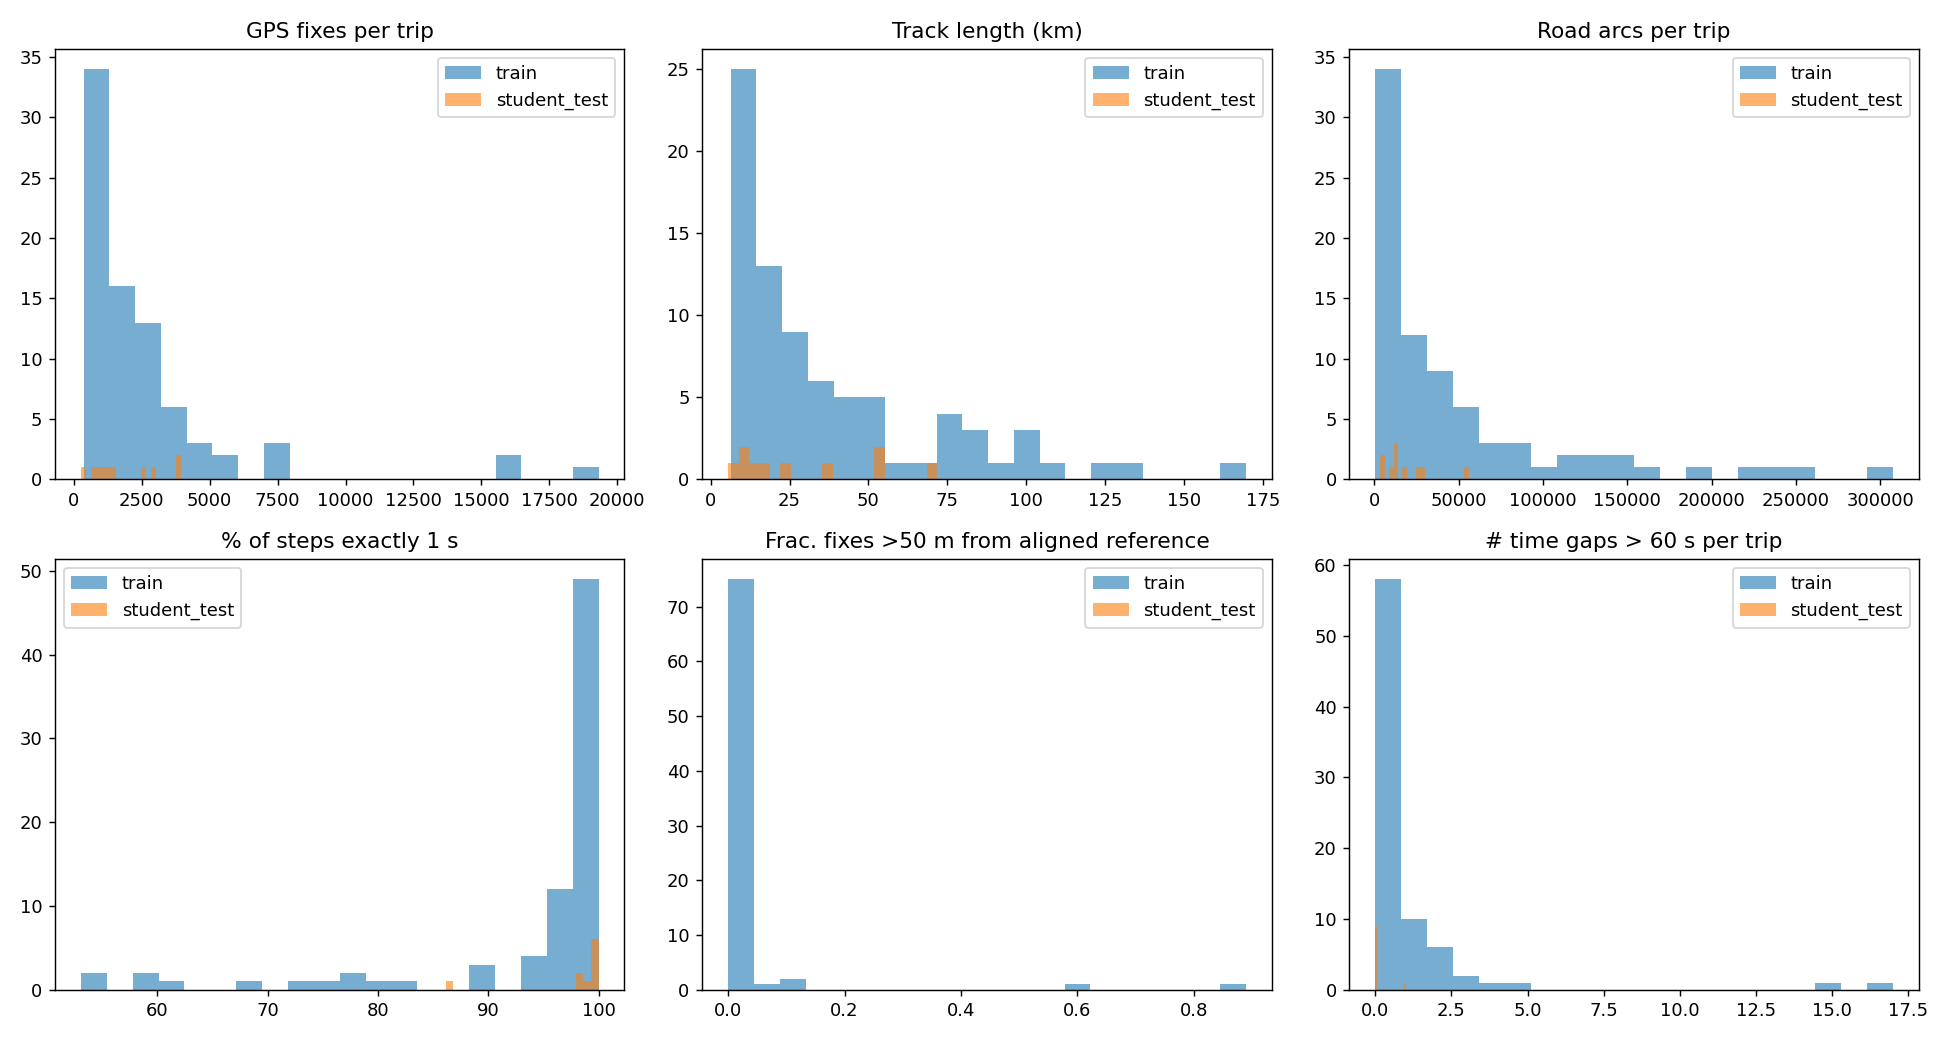

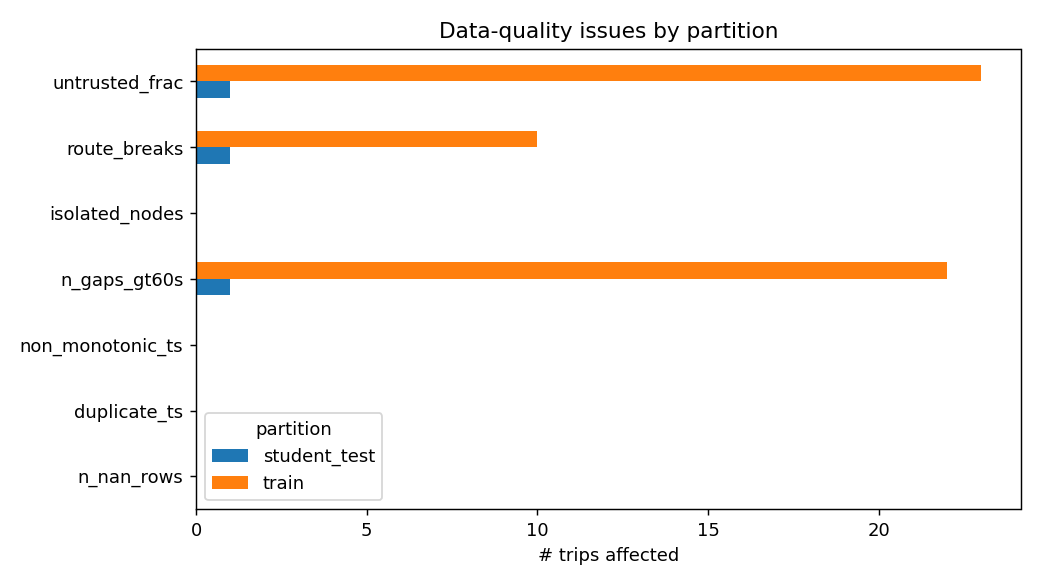

,partition,trip,n_obs,max_gap_s,n_gaps_gt60s,pct_dt_eq_1
72,train,90,536,153064.0,1,58.13
61,train,78,2909,52810.0,1,75.52
55,train,69,2067,2658.0,2,98.94
16,train,21,15783,2161.0,2,99.96
8,train,11,2828,909.0,1,99.96
34,train,42,7739,670.0,17,98.95
64,train,81,3224,536.0,15,71.98
18,train,24,801,458.0,2,97.12


In [5]:
display(Image(str(OUT/'eda_distributions.png')))
display(Image(str(OUT/'eda_quality.png')))
inv.sort_values('max_gap_s', ascending=False)[['partition','trip','n_obs','max_gap_s','n_gaps_gt60s','pct_dt_eq_1']].head(8)

## 4. GPS trajectories and road networks (train)

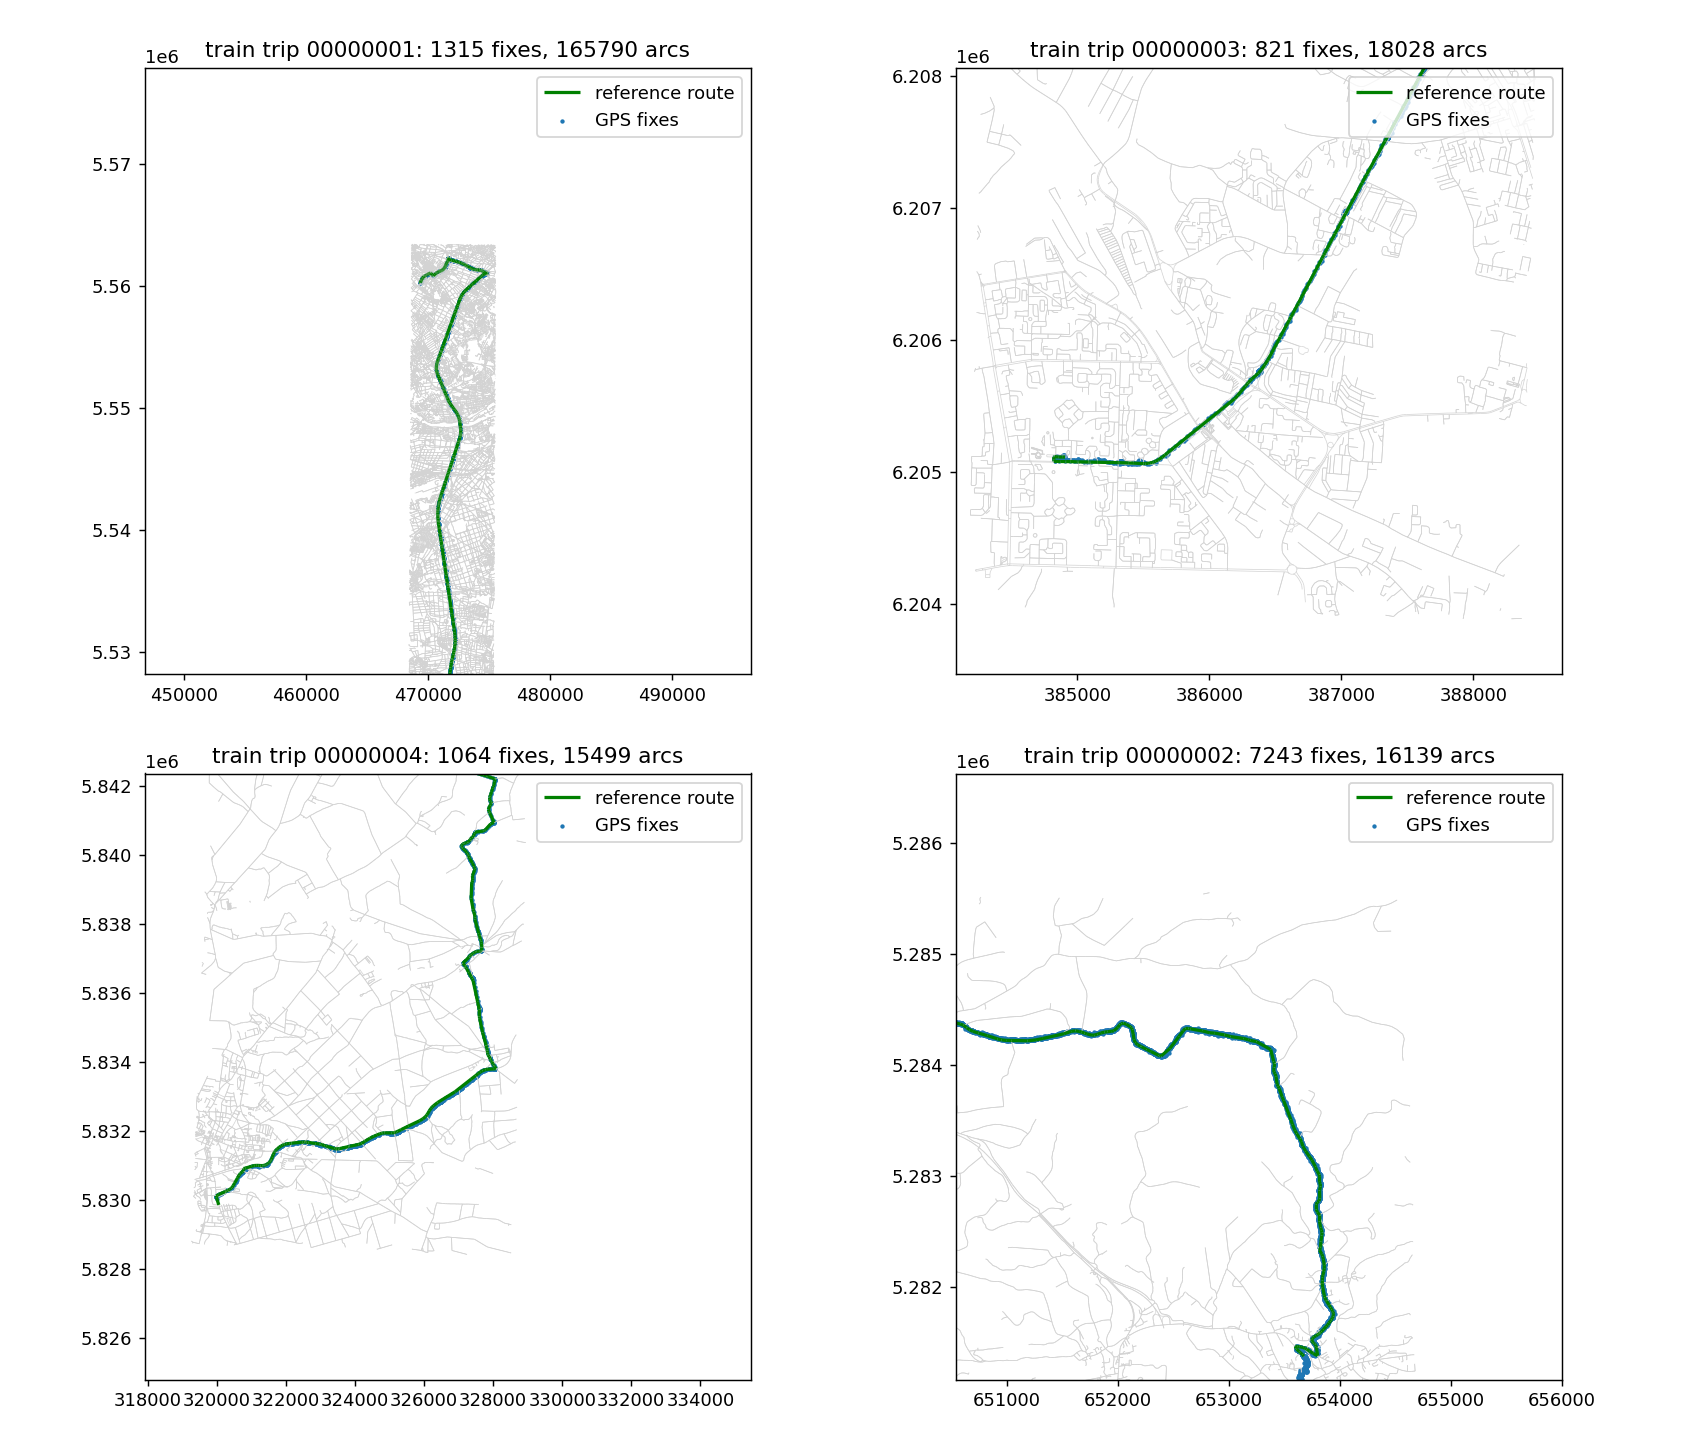

In [6]:
display(Image(str(OUT/'eda_trajectories_network.png')))

## 5. Road-network size and connectivity (per-trip graph)

In [7]:
g = build_graph(trip['nodes'], trip['arcs'], trip['nxy'])
print('DiGraph', g.number_of_nodes(), 'nodes', g.number_of_edges(), 'arcs')
inv[['partition','n_nodes','n_arcs','n_components','largest_comp_frac','isolated_nodes','two_way_frac','mean_arc_len_m']].groupby('partition').describe().T.round(3).head(40)

DiGraph 9138 nodes 18022 arcs


partition                student_test       train
n_nodes           count        10.000      80.000
                  mean       9068.900   24168.562
                  std        7452.176   32272.296
                  min        1770.000     299.000
                  25%        4908.000    3487.750
                  50%        6596.500    9608.000
                  75%       11844.250   28846.750
                  max       26635.000  155003.000
n_arcs            count        10.000      80.000
                  mean      18504.100   48461.300
                  std       15496.930   64738.837
                  min        3577.000     649.000
                  25%       10292.250    7061.750
                  50%       13145.000   19526.500
                  75%       24818.500   58003.250
                  max       56027.000  307392.000
n_components      count        10.000      80.000
                  mean         22.700      39.012
                  std          29.182      60.682
                  min           5.000       1.000
                  25%           7.250       9.750
                  50%          11.000      20.000
                  75%          21.750      42.250
                  max         100.000     421.000
largest_comp_frac count        10.000      80.000
                  mean          0.964       0.969
                  std           0.034       0.039
                  min           0.874       0.693
                  25%           0.964       0.963
                  50%           0.971       0.981
                  75%           0.983       0.987
                  max           0.991       1.000
isolated_nodes    count        10.000      80.000
                  mean          0.000       0.000
                  std           0.000       0.000
                  min           0.000       0.000
                  25%           0.000       0.000
                  50%           0.000       0.000
                  75%           0.000       0.000
                  max           0.000       0.000

## 6. Reference route: structure, alignment and limitations
`.route` is an ordered arc list without timestamps -> monotone DP alignment (`src/data/labels.py`). Fixes farther than 50 m from their aligned reference arc are flagged untrusted.

In [8]:
al = reference_alignment(trip)
display(al.head())
print('trusted fraction', al.trusted.mean().round(4))
inv[inv.untrusted_frac>0.05][['partition','trip','n_obs','untrusted_frac','route_breaks']]

,obs_idx,ref_arc,route_pos,align_dist,trusted
0,0,12,0,7.195163,True
1,1,12,0,2.831105,True
2,2,12,0,0.537170,True
3,3,12,0,3.235300,True
4,4,12,0,1.488307,True


trusted fraction 1.0


,partition,trip,n_obs,untrusted_frac,route_breaks
1,train,2,7243,0.1198,1
26,train,33,5844,0.5902,1
35,train,43,2322,0.0719,0
44,train,54,19313,0.8890,0
53,train,66,4325,0.0902,0


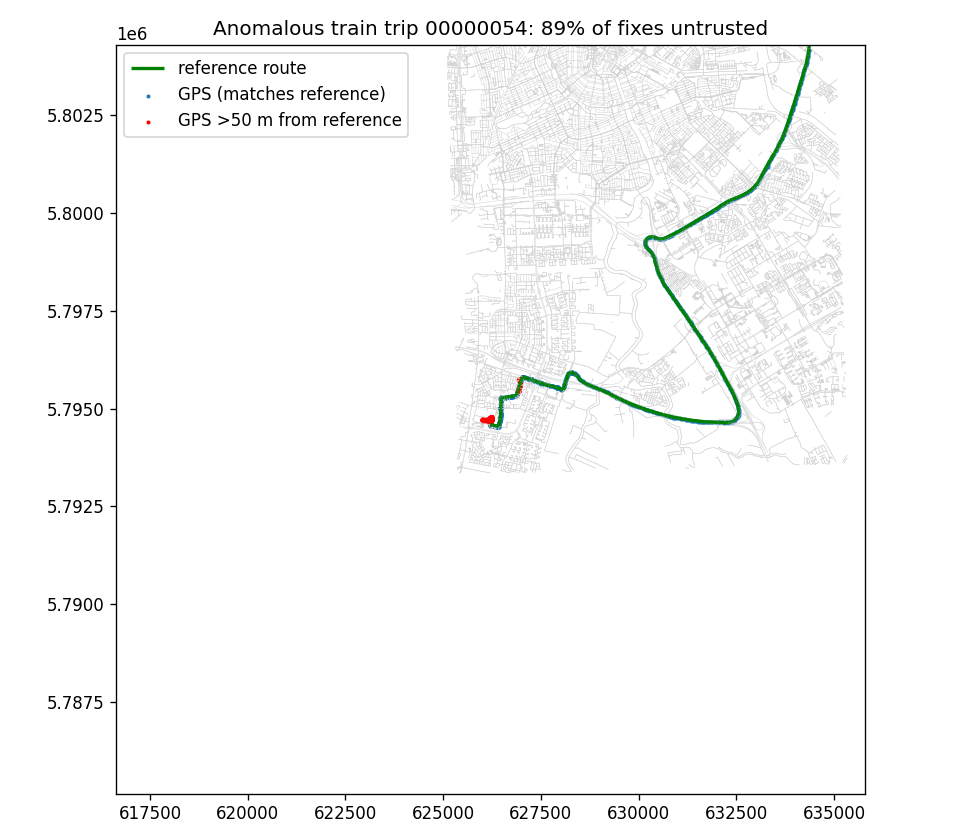

In [9]:
display(Image(str(OUT/'anomaly_trip_00000054.png')))

## 7. Candidate generation: miss rate vs radius R and k (train, trusted fixes)
By construction trusted fixes lie within 50 m of the reference arc, so the sweep saturates for R >= 50 m; R = 100 m is kept as a safety margin for noisier unseen trips, K = 10 (miss 0.71 % vs 0.49 % for k = 15, with fewer HMM states).

,1,3,5,10,15,20
R,,,,,,
25,46.212,6.380,3.605,2.581,2.441,2.383
50,45.545,4.978,1.970,0.707,0.492,0.284
75,45.545,4.978,1.970,0.707,0.492,0.284
100,45.545,4.978,1.970,0.707,0.492,0.284
150,45.545,4.978,1.970,0.707,0.492,0.284
200,45.545,4.978,1.970,0.707,0.492,0.284


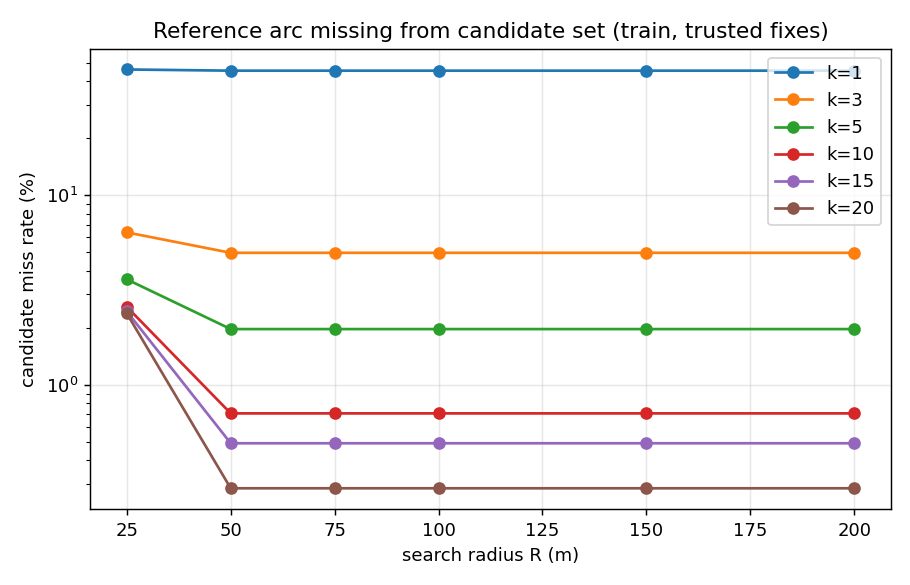

In [10]:
display(pd.read_csv(OUT/'candidate_miss_sweep.csv', index_col=0).round(3))
display(Image(str(OUT/'candidate_miss_sweep.png')))

## 8. Features (label-free `build_candidates`) and labels

In [11]:
c = build_candidates(trip)
print(c.shape, 'candidates per fix:', round(len(c)/len(trip['xy']),2))
c.head()

(8089, 35) candidates per fix: 9.85


,trip_id,obs_idx,t,lon,lat,arc_id,d,rank,arc_len,frac,n_cand,d_minus_min,d_ratio,speed_w1,cos_w1,speed_w3,cos_w3,d_k-3,d_k-2,d_k-1,adv_-1,adv_ratio_-1,d_k1,adv_1,adv_ratio_1,d_k2,d_k3,d_ctx_mean,d_ctx_max,d_ctx_n30,out_deg_head,in_deg_tail,has_reverse,dt_prev,dt_next
0,00000003,0,1.0,37.201398,56.007471,9853,1.174710,0.0,15.820168,0.670994,10.0,0.000000,0.190245,5.335041,0.317666,3.503097,-0.995325,1.174710,1.174710,1.174710,-0.0,-0.0,3.883989,1.694763,0.317666,5.619958,0.159730,2.197968,5.619958,6.0,1.0,1.0,0.0,0.0,1.0
1,00000003,0,1.0,37.201398,56.007471,9852,5.335838,1.0,18.534294,0.000000,10.0,4.161128,0.864144,5.335041,-0.027894,3.503097,-0.967806,5.335838,5.335838,5.335838,-0.0,-0.0,5.235131,-0.148818,-0.027894,8.016835,15.665901,7.487564,15.665901,6.0,1.0,1.0,0.0,0.0,1.0
2,00000003,0,1.0,37.201398,56.007471,12,7.195163,2.0,75.061844,0.422102,10.0,6.020452,1.165263,5.335041,0.575220,3.503097,-0.926296,7.195163,7.195163,7.195163,-0.0,-0.0,2.831105,3.068820,0.575220,0.537170,3.235300,4.698177,7.195163,6.0,3.0,3.0,1.0,0.0,1.0
3,00000003,0,1.0,37.201398,56.007471,5525,7.195163,3.0,75.061844,0.577898,10.0,6.020452,1.165263,5.335041,-0.575220,3.503097,0.926296,7.195163,7.195163,7.195163,-0.0,-0.0,2.831105,-3.068820,-0.575220,0.537170,3.235300,4.698177,7.195163,6.0,3.0,3.0,1.0,0.0,1.0
4,00000003,0,1.0,37.201398,56.007471,13,10.680045,4.0,22.056255,1.000000,10.0,9.505335,1.729643,5.335041,0.457069,3.503097,-0.969366,10.680045,10.680045,10.680045,-0.0,-0.0,12.908200,2.438484,0.457069,11.560927,0.222629,9.455316,12.908200,6.0,1.0,3.0,0.0,0.0,1.0


In [12]:
ref = reference_arc_per_obs(trip)
c['label'] = (c.arc_id.values == ref.values[c.obs_idx.values]).astype(int)
print('positive rate', c.label.mean().round(4), '| fixes with a positive candidate', c.groupby('obs_idx').label.max().mean().round(4))
c.groupby('label')[['d','cos_w3','d_ctx_mean','adv_ratio_1']].mean().round(3)

positive rate

 0.1009 | fixes with a positive candidate 0.9939


,d,cos_w3,d_ctx_mean,adv_ratio_1
label,,,,
0,22.351,-0.031,26.051001,-0.024
1,5.408,0.604,6.941000,0.437


## 9. Interactive Folium map
`results/eda/folium_eda_student_test_00000007.html` (student_test) and `folium_eda_train_00000003.html` (train): raw GPS, road network clipped to the trip bbox, reference route, layer control, legend.

In [13]:
from IPython.display import IFrame
IFrame(str(OUT/'folium_eda_student_test_00000007.html'), width=900, height=500)